# Amazon Prime TV Shows and Movies — Machine Learning
**Task:** Binary classification of titles into IMDb rating >= 7.0 versus below 7.0.

## Objective and target definition
The model estimates whether a title belongs to the high-rating group using catalogue metadata and aggregated credits. This is a supervised classification task, not a recommendation engine. Titles without IMDb ratings cannot be used to define the target and are excluded from model fitting.

**Important:** IMDb score itself is excluded from the features to prevent target leakage. The target threshold is an analytical choice, not an official Amazon category.

## 1. Load, merge and prepare datasets

In [4]:
from google.colab import files
import os, ast, warnings, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
sns.set_theme(style="whitegrid")

# Check and upload titles.csv if missing
if not os.path.exists("/content/titles.csv"):
    print("Please upload titles.csv:")
    uploaded_titles = files.upload()

# Check and upload credits.csv if missing
if not os.path.exists("/content/credits.csv"):
    print("Please upload credits.csv:")
    uploaded_credits = files.upload()

titles = pd.read_csv("/content/titles.csv", low_memory=False)
credits = pd.read_csv("/content/credits.csv", low_memory=False)

# Drop rows where 'id' is missing
titles = titles.dropna(subset=["id"])
credits = credits.dropna(subset=["id"])

credits["role_norm"] = credits["role"].astype(str).str.upper()
credit_summary = credits.groupby("id").agg(
    actor_count=("role_norm", lambda s: int((s == "ACTOR").sum())),
    director_count=("role_norm", lambda s: int((s == "DIRECTOR").sum()))
).reset_index()

# Perform a 'many_to_one' merge since 'id' is unique in credit_summary but may contain duplicates in titles
df = titles.merge(credit_summary, on="id", how="left", validate="many_to_one")
df[["actor_count","director_count"]] = df[["actor_count","director_count"]].fillna(0)

def parse_list(value):
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else []
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []

df["genres_list"] = df["genres"].apply(parse_list)
df["countries_list"] = df["production_countries"].apply(parse_list)
df["genre_count"] = df["genres_list"].str.len()
df["country_count"] = df["countries_list"].str.len()
print("Merged data shape:", df.shape)

Merged data shape: (9871, 21)


## 2. Target and feature engineering

In [5]:
# Keep only rows with known IMDb score to create the binary target.
data = df.dropna(subset=["imdb_score"]).copy()
data["high_rating"] = (data["imdb_score"] >= 7.0).astype(int)
# Expand genres into binary indicators and retain the 10 most common countries.
genre_values = sorted({g for values in data["genres_list"] for g in values})
top_countries = pd.Series([c for values in data["countries_list"] for c in values]).value_counts().head(10).index.tolist()
for genre in genre_values:
    data["genre_" + genre] = data["genres_list"].apply(lambda values: int(genre in values))
for country in top_countries:
    data["country_" + country] = data["countries_list"].apply(lambda values: int(country in values))
numeric_features = ["release_year","runtime","seasons","tmdb_score","tmdb_popularity",
                    "actor_count","director_count","genre_count","country_count"]
categorical_features = ["type","age_certification"]
feature_columns = numeric_features + categorical_features + ["genre_" + g for g in genre_values] + ["country_" + c for c in top_countries]
X = data[feature_columns]
y = data["high_rating"]
print("Rows used:", len(data), "| Features:", X.shape[1])
print("Target distribution:")
display(y.value_counts().rename(index={0:"IMDb < 7",1:"IMDb >= 7"}).to_frame("count"))

Rows used: 8850 | Features: 40
Target distribution:


,count
high_rating,
IMDb < 7,6648
IMDb >= 7,2202


## 3. Train/test split and preprocessing

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
], remainder="passthrough")
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (7080, 40) Test: (1770, 40)


## 4. Train and compare three classification models

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42,
        class_weight="balanced_subsample", min_samples_leaf=2, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=42,
        class_weight="balanced", min_samples_leaf=2, n_jobs=-1)
}
pipelines, results = {}, []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    probability = pipe.predict_proba(X_test)[:, 1]
    pipelines[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probability)
    })
results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
1,Random Forest,0.8305,0.6277,0.7818,0.6964,0.8976
2,Extra Trees,0.8034,0.5799,0.7591,0.6575,0.8713
0,Logistic Regression,0.7718,0.5282,0.7659,0.6252,0.8542


## 5. Model evaluation

Confusion Matrix Values:
[[1126  204]
 [  96  344]]
Selected baseline model: Random Forest
              precision    recall  f1-score   support

    IMDb < 7       0.92      0.85      0.88      1330
   IMDb >= 7       0.63      0.78      0.70       440

    accuracy                           0.83      1770
   macro avg       0.77      0.81      0.79      1770
weighted avg       0.85      0.83      0.84      1770



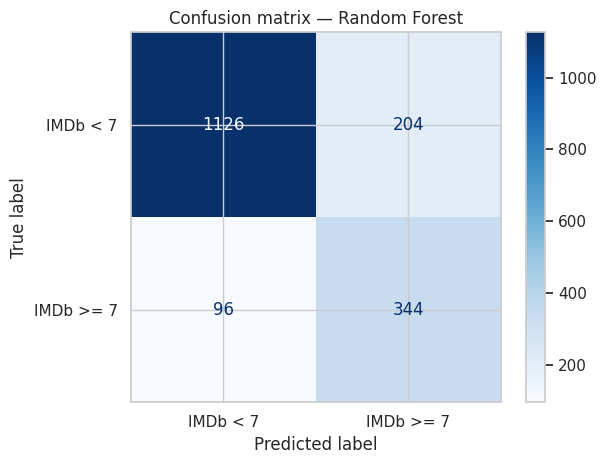

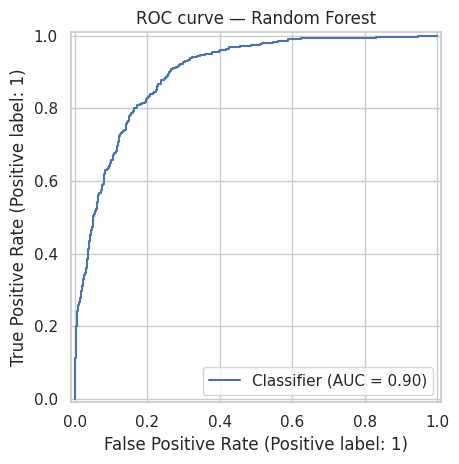

In [14]:
best_name = results_df.iloc[0]["Model"]
best_model = pipelines[best_name]
best_pred = best_model.predict(X_test)
from sklearn.metrics import confusion_matrix
print("Confusion Matrix Values:")
print(confusion_matrix(y_test, best_pred))
best_prob = best_model.predict_proba(X_test)[:, 1]
print("Selected baseline model:", best_name)
print(classification_report(y_test, best_pred, target_names=["IMDb < 7","IMDb >= 7"]))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["IMDb < 7","IMDb >= 7"], cmap="Blues")
plt.title("Confusion matrix — " + best_name); plt.tight_layout(); plt.show()
RocCurveDisplay.from_predictions(y_test, best_prob)
plt.title("ROC curve — " + best_name); plt.tight_layout(); plt.show()

## 6. Hyperparameter tuning — RandomizedSearchCV

In [9]:
# Tune Random Forest using stratified cross-validation on the training split only.
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42, class_weight="balanced_subsample",
                                     n_jobs=-1, min_samples_leaf=2))
])
param_distributions = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.7]
}
search = RandomizedSearchCV(
    rf_pipeline, param_distributions, n_iter=10, scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
tuned_pred = tuned_model.predict(X_test)
tuned_prob = tuned_model.predict_proba(X_test)[:,1]
print("Best parameters:", search.best_params_)
print("Best CV F1:", search.best_score_)
print("Tuned test F1:", f1_score(y_test, tuned_pred))
print("Tuned test ROC-AUC:", roc_auc_score(y_test, tuned_prob))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30}
Best CV F1: 0.6947672870855883
Tuned test F1: 0.6867704280155642
Tuned test ROC-AUC: 0.8967840054682159


## 7. Model explainability — permutation importance

,feature,importance_mean,importance_std
3,tmdb_score,0.147949,0.011502
4,tmdb_popularity,0.035678,0.004880
15,genre_documentation,0.030477,0.005444
9,type,0.021162,0.003073
0,release_year,0.016197,0.002685
27,genre_thriller,0.009478,0.005417
21,genre_horror,0.007592,0.004423
5,actor_count,0.007431,0.002315
16,genre_drama,0.005280,0.002818
7,genre_count,0.003265,0.002190


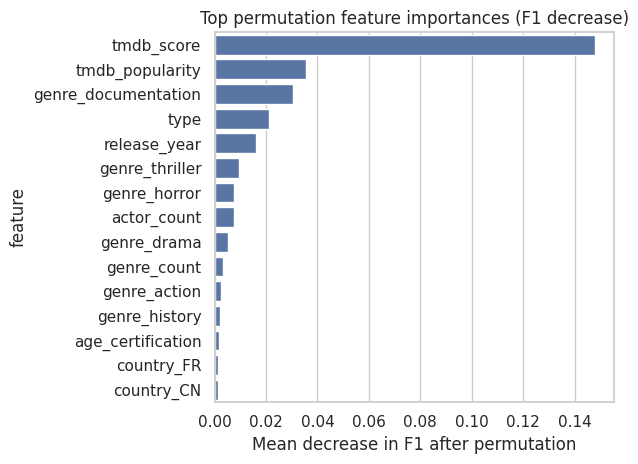

In [10]:
# Permutation importance is computed on the held-out test set.
importance = permutation_importance(
    tuned_model, X_test, y_test, n_repeats=5, random_state=42,
    scoring="f1", n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False).head(15)
display(importance_df)
sns.barplot(data=importance_df, x="importance_mean", y="feature")
plt.title("Top permutation feature importances (F1 decrease)")
plt.xlabel("Mean decrease in F1 after permutation"); plt.tight_layout(); plt.show()

## 8. Save model and sanity-check an unseen row

In [11]:
# Persist the complete preprocessing + model pipeline.
joblib.dump(tuned_model, "/content/amazon_prime_high_rating_model.joblib")
loaded_model = joblib.load("/content/amazon_prime_high_rating_model.joblib")
sample = X_test.iloc[[0]]
print("Predicted high-rating probability:", loaded_model.predict_proba(sample)[0,1])
print("Predicted class:", int(loaded_model.predict(sample)[0]))
print("Actual class:", int(y_test.iloc[0]))
files.download("/content/amazon_prime_high_rating_model.joblib")

Predicted high-rating probability: 0.007518198229111177
Predicted class: 0
Actual class: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Business interpretation and limitations
- **Precision:** Of titles predicted as high-rated, the proportion that are actually high-rated. Useful when a curated shortlist should avoid too many false positives.
- **Recall:** Of all actually high-rated titles, the proportion found by the model. Useful when missing promising titles is costly.
- **F1:** Harmonic mean of precision and recall; a balanced selection metric for this binary task.
- **ROC-AUC:** Measures ranking ability across thresholds; it does not establish business value by itself.
- The model learns associations in the supplied metadata. It does not prove that a genre, cast size or country causes a higher rating.
- The catalogue data does not include watch time, customer satisfaction, churn, subscription conversion or licensing cost. Do not use this model alone for acquisition or recommendation decisions.
- IMDb rating coverage is incomplete; titles without scores were excluded from supervised training. Metadata quality and rating bias can affect results.

## Conclusion
After executing all cells, record the actual test metrics and tuning results here. The model with the strongest validation/test performance should be selected, while business deployment should wait for external validation, monitoring, fairness checks and user engagement data.